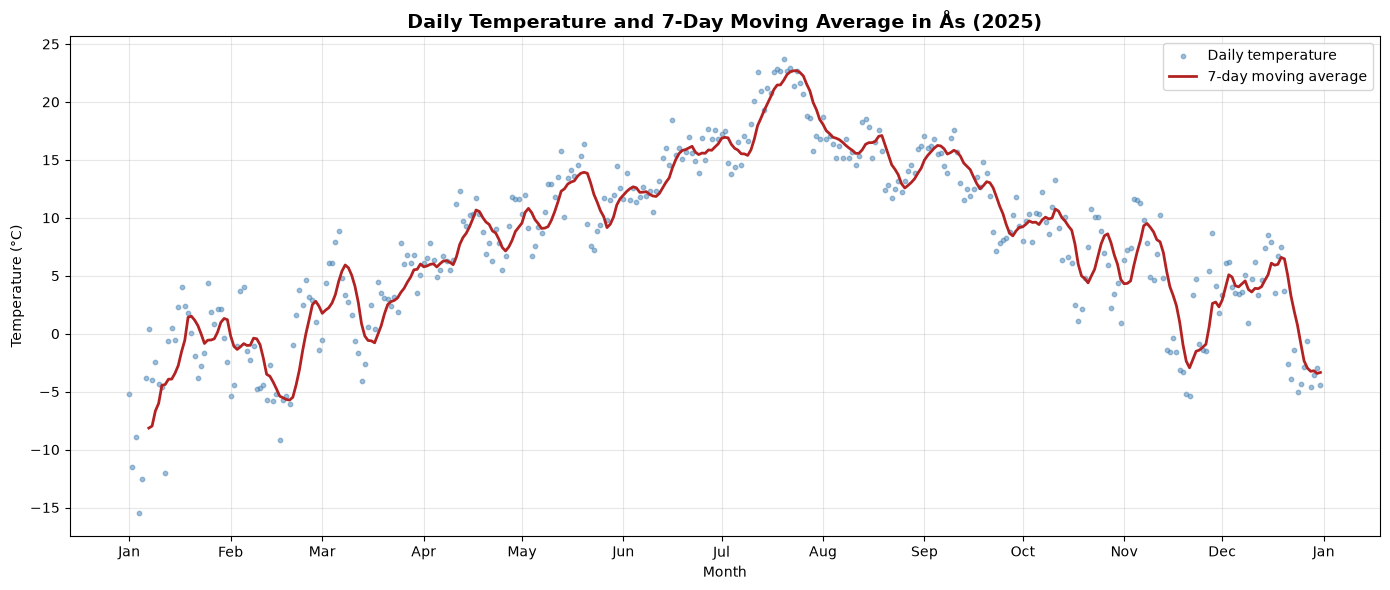

In [2]:

# INF201 - Deliverable 1
# Task 5: Moving Average Temperature

"""

FILL INN LATER

"""

import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Read the client ID from secrets.txt
with open("secrets.txt", "r") as f:
    client_id = f.read().strip()

endpoint = "https://frost.met.no/observations/v0.jsonld"

# Request daily mean temperature for 2025
parameters = {"sources": "SN17850", "elements": "mean(air_temperature P1D)", "referencetime": "2025-01-01/2026-01-01"}

# Get temperature data from Frost
response = requests.get(endpoint, params=parameters, auth=(client_id, ""), timeout=30)

rows = []

# Go through the temperature observations
for item in response.json()["data"]:
    for observation in item["observations"]:
        if observation["timeOffset"] == "PT0H":
            rows.append({
                "date": item["referenceTime"],
                "temperature": observation["value"]
            })


df = pd.DataFrame(rows, columns=["date", "temperature"])
df["date"] = pd.to_datetime(df["date"], utc=True)
df = df[df["date"].dt.year == 2025]
df = df.sort_values("date")


# Use one row for every day of 2025
all_dates = pd.date_range("2025-01-01", "2025-12-31", freq="D", tz="UTC")
df = df.set_index("date").reindex(all_dates)
df.index.name = "date"


# Function to calculate the 7-day moving average
def moving_average(temperatures):
    return temperatures.rolling(window=7, min_periods=7).mean()


# Calculate the moving average
df["moving_average"] = moving_average(df["temperature"])


# Create the plot
fig, ax = plt.subplots(figsize=(14, 6))

# Daily temperatures shown as points
ax.scatter(
    df.index,
    df["temperature"],
    color="steelblue",
    s=10,
    alpha=0.5,
    label="Daily temperature"
)

# Moving average shown as a line
ax.plot(
    df.index,
    df["moving_average"],
    color="firebrick",
    linewidth=2,
    label="7-day moving average"
)

# Labels and title
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Daily Temperature and 7-Day Moving Average in Ås (2025)",
             fontsize=14, fontweight="bold")

# Show month names on the x-axis
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()
